# Analyse du churn — abonnements de services numériques

**Auteure :** Danielle OUATTARA · **Données :** [Telco Customer Churn (Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

**Question :** quels clients risquent de résilier, pourquoi, et combien de revenu mensuel est en jeu ?

Ce notebook reproduit en Python l'analyse menée en SQL dans `sql/churn_queries.sql`.

| Étape | Contenu | Équivalent SQL |
|---|---|---|
| 1 | Import et contrôle | Bloc 0 |
| 2 | Nettoyage et enrichissement | Bloc 1 |
| 3 | Analyse exploratoire | Blocs 2 à 7 |
| 4 | Visualisation | — |
| 5 | Conclusion | — |

## 1. Import des bibliothèques et des données

In [1]:
import pandas as pd                      # pandas : la bibliothèque qui manipule des tableaux (comme Excel)
import matplotlib.pyplot as plt          # matplotlib : la bibliothèque qui dessine les graphiques

pd.set_option("display.max_columns", None)   # afficher toutes les colonnes au lieu d'en masquer une partie

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")  # lit le CSV et le range dans un tableau nommé df

In [2]:
print(df.shape)                          # affiche (nombre de lignes, nombre de colonnes) : on attend (7043, 21)
df.head()                                # affiche les 5 premières lignes pour voir à quoi ressemblent les données

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()                                # liste chaque colonne avec son type : on repère que TotalCharges est du texte (object)

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 2. Nettoyage
`TotalCharges` est stockée en texte car 11 clients (ancienneté = 0 mois) ont une valeur vide.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")  # convertit en nombre ; les vides deviennent NaN (valeur manquante)
print(df["TotalCharges"].isna().sum())                                    # compte les valeurs manquantes : on attend 11
df["TotalCharges"] = df["TotalCharges"].fillna(0)                         # remplace ces manquants par 0 (clients pas encore facturés)

11


In [5]:
df["churn_flag"] = (df["Churn"] == "Yes").astype(int)   # crée une colonne 1 si le client est parti, 0 sinon

In [6]:
bornes = [-1, 6, 12, 24, 48, 100]                        # limites des tranches d'ancienneté, en mois
etiquettes = ["0-6 mois", "7-12 mois", "13-24 mois", "25-48 mois", "49 mois et +"]  # nom de chaque tranche
df["tranche_anciennete"] = pd.cut(df["tenure"], bins=bornes, labels=etiquettes)    # range chaque client dans sa tranche

In [7]:
options = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]  # les 4 options de sécurité/support
df["nb_options_securite"] = (df[options] == "Yes").sum(axis=1)                  # compte, ligne par ligne, les « Yes » parmi ces 4 colonnes

In [8]:
print(df.duplicated(subset="customerID").sum())   # vérifie qu'aucun client n'apparaît deux fois : on attend 0

0


## 3. Analyse exploratoire (EDA)
### 3.1 KPI globaux

In [9]:
taux_churn = df["churn_flag"].mean()                                  # la moyenne d'une colonne 0/1 = le taux de churn
mrr_total = df["MonthlyCharges"].sum()                                # revenu mensuel total de la base
mrr_perdu = df.loc[df["churn_flag"] == 1, "MonthlyCharges"].sum()     # revenu mensuel des seuls clients partis

print(f"Taux de churn : {taux_churn:.1%}")                            # :.1% = format pourcentage, 1 décimale
print(f"MRR total     : {mrr_total:,.0f} $")                          # :,.0f = séparateur de milliers, 0 décimale
print(f"MRR perdu     : {mrr_perdu:,.0f} $ ({mrr_perdu / mrr_total:.1%} du MRR)")

Taux de churn : 26.5%
MRR total     : 456,117 $
MRR perdu     : 139,131 $ (30.5% du MRR)


### 3.2 Churn par dimension

In [10]:
def taux_par(colonne):                                   # définit une petite fonction réutilisable
    return (df.groupby(colonne, observed=True)["churn_flag"]   # regroupe les clients par valeur de la colonne
              .agg(nb_clients="count", taux_churn="mean")      # compte les clients et calcule le taux de churn par groupe
              .sort_values("taux_churn", ascending=False))     # trie du plus risqué au moins risqué

In [11]:
taux_par("Contract")                     # churn par type de contrat

,nb_clients,taux_churn
Contract,,
Month-to-month,3875,0.427097
One year,1473,0.112695
Two year,1695,0.028319


In [12]:
taux_par("tranche_anciennete")           # churn par tranche d'ancienneté

,nb_clients,taux_churn
tranche_anciennete,,
0-6 mois,1481,0.529372
7-12 mois,705,0.358865
13-24 mois,1024,0.287109
25-48 mois,1594,0.203890
49 mois et +,2239,0.095132


In [13]:
taux_par("PaymentMethod")                # churn par mode de paiement

,nb_clients,taux_churn
PaymentMethod,,
Electronic check,2365,0.452854
Mailed check,1612,0.191067
Bank transfer (automatic),1544,0.167098
Credit card (automatic),1522,0.152431


In [14]:
internet = df[df["InternetService"] != "No"]              # garde les 5 517 clients abonnés à Internet (les options n'existent que pour eux)
print(len(internet))                                     # on attend 5517
(internet.groupby("nb_options_securite")["churn_flag"]   # regroupe ces clients par nombre d'options souscrites
         .agg(nb_clients="count", taux_churn="mean"))    # compte les clients et calcule le taux de churn par groupe

5517


,nb_clients,taux_churn
nb_options_securite,,
0,1267,0.566693
1,1467,0.388548
2,1372,0.237609
3,941,0.124336
4,470,0.053191


### 3.3 Matrice de priorisation : contrat × ancienneté

In [15]:
matrice = pd.pivot_table(df,                         # tableau croisé dynamique, comme dans Excel
                         index="Contract",           # en lignes : le type de contrat
                         columns="tranche_anciennete",  # en colonnes : la tranche d'ancienneté
                         values="churn_flag",        # la valeur analysée
                         aggfunc="mean",             # la moyenne = le taux de churn
                         observed=True)              # n'affiche que les combinaisons existantes
matrice.style.format("{:.0%}").background_gradient(cmap="Reds")  # affiche en % avec un dégradé de rouge

tranche_anciennete,0-6 mois,7-12 mois,13-24 mois,25-48 mois,49 mois et +
Contract,,,,,
Month-to-month,55%,42%,38%,33%,26%
One year,10%,11%,8%,11%,13%
Two year,0%,0%,0%,2%,3%


## 4. Visualisation

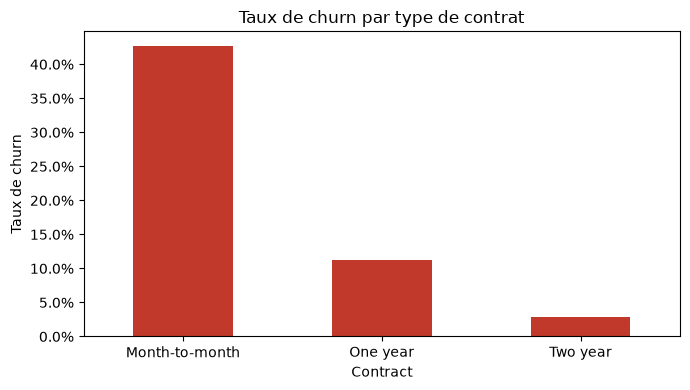

In [16]:
churn_contrat = taux_par("Contract")["taux_churn"]       # récupère uniquement la colonne des taux

fig, ax = plt.subplots(figsize=(7, 4))                   # crée une zone de dessin de 7 × 4 pouces
churn_contrat.plot(kind="bar", ax=ax, color="#C0392B")   # dessine un histogramme rouge
ax.set_title("Taux de churn par type de contrat")        # titre du graphique
ax.set_ylabel("Taux de churn")                           # libellé de l'axe vertical
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))  # axe vertical en %
plt.xticks(rotation=0)                                   # libellés de l'axe horizontal à l'horizontale
plt.tight_layout()                                       # ajuste les marges
plt.show()                                               # affiche le graphique

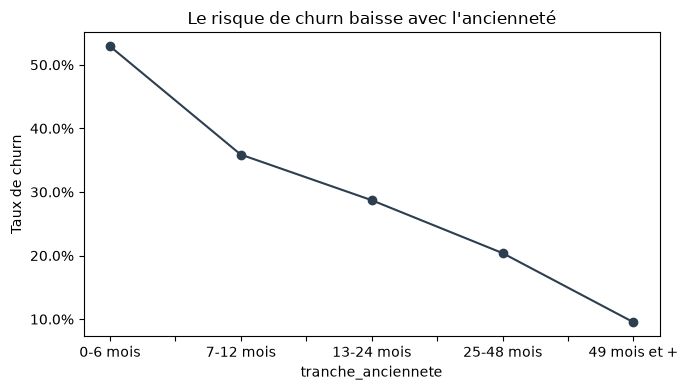

In [17]:
churn_anc = taux_par("tranche_anciennete")["taux_churn"].sort_index()   # sort_index remet les tranches dans l'ordre

fig, ax = plt.subplots(figsize=(7, 4))
churn_anc.plot(kind="line", marker="o", ax=ax, color="#2C3E50")         # courbe avec un point par tranche
ax.set_title("Le risque de churn baisse avec l'ancienneté")
ax.set_ylabel("Taux de churn")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

## 5. Conclusion

Les résultats sont identiques à ceux obtenus en SQL.

1. **Le contrat est le premier facteur de risque.** Les contrats mensuels churnent à 42,7 %, contre 2,8 % pour les contrats de 2 ans, soit 15 fois plus. Ils représentent environ 89 % des départs.
2. **Les 6 premiers mois sont décisifs.** Le churn atteint 52,9 % entre 0 et 6 mois d'ancienneté, contre 9,5 % au-delà de 4 ans.
3. **Les options de sécurité et de support retiennent les clients.** Parmi les abonnés à Internet, le churn passe de 56,7 % sans option à 5,3 % avec les 4 options.

Au total, les clients partis représentaient 139 131 $ de revenu mensuel, soit 30,5 % du MRR.

**Recommandations :** voir le README, section 7.